In [2]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from import_folder import import_single_noiselevel_data, PQD_INDICES

# 1. Load Data
noiseless_data = import_single_noiselevel_data(r'SNR_noiseless')

# 2. Separate Features and Label
X = noiseless_data.drop(columns=['label'])
y = noiseless_data['label']

# 3. Train-Test Split (before scaling to prevent data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Feature Scaling
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), index=X_train.index, columns=X.columns)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=X.columns)

print("Training features shape:", X_train_scaled.shape)
print("Testing features shape:", X_test_scaled.shape)

Training features shape: (1072, 8)
Testing features shape: (269, 8)


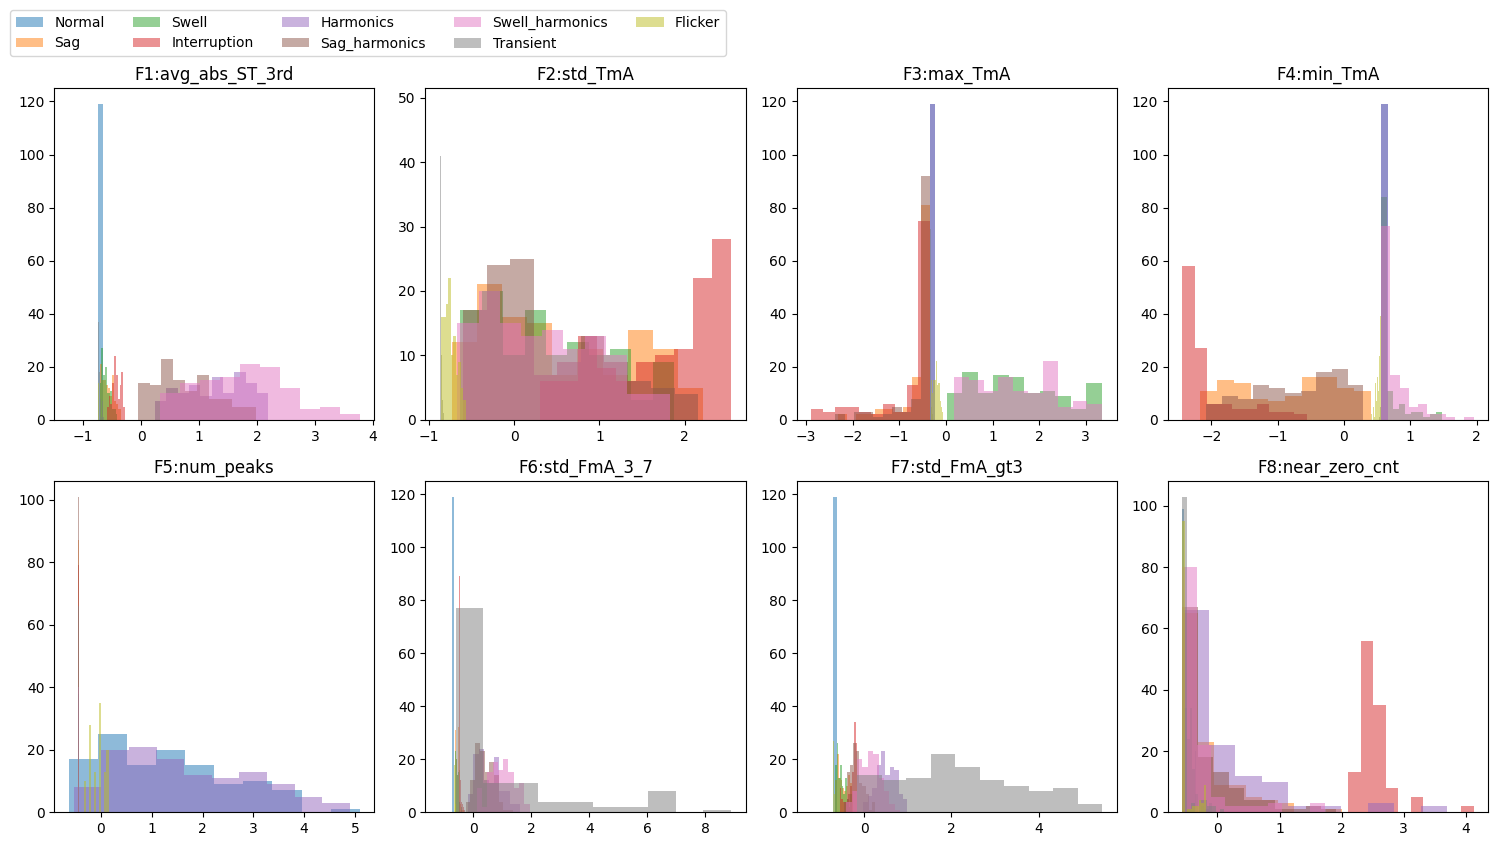

In [3]:
import matplotlib.pyplot as plt

# 8 subplots: Each subplot will shows the histogram distribution of a feature for each label
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

for i, feature in enumerate(X_train_scaled.columns):
    for PQD, PQD_index in PQD_INDICES.items():
        axes[i].hist(X_train_scaled[y_train == PQD_index][feature], alpha=0.5, label=PQD)
    axes[i].set_title(feature)
# one legend outside the subplots on the bottom
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper left', ncol=5, bbox_to_anchor=(0, 1.06))
fig.tight_layout()


C:\Users\paulk\AppData\Local\Temp\ipykernel_3576\110606921.py:24: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


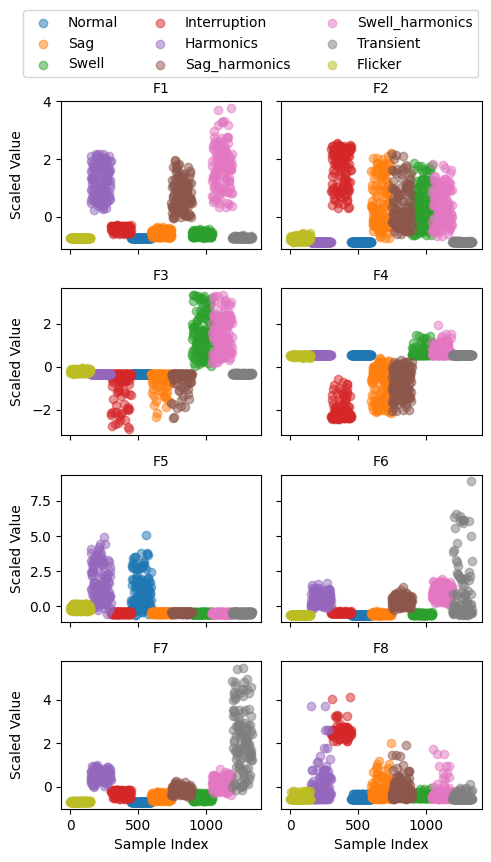

In [19]:
# 8 subplots (one for each feature): Each subplot will shows the value of the feature for each label
fig, axes = plt.subplots(4, 2, figsize=(5, 8), sharex='col', sharey='row', constrained_layout=True)
axes = axes.flatten()

for i, feature in enumerate(X_train_scaled.columns):
    for PQD, PQD_index in PQD_INDICES.items():
        axes[i].scatter(X_train_scaled[y_train == PQD_index].index, X_train_scaled[y_train == PQD_index][feature], alpha=0.5, label=PQD)
    axes[i].set_title(feature[:2], fontsize=10)  

# x labels
axes[6].set_xlabel('Sample Index', fontsize=10)
axes[7].set_xlabel('Sample Index', fontsize=10)

# y labels
axes[0].set_ylabel('Scaled Value', fontsize=10)
axes[2].set_ylabel('Scaled Value', fontsize=10)
axes[4].set_ylabel('Scaled Value', fontsize=10)
axes[6].set_ylabel('Scaled Value', fontsize=10)
# align y labels 
fig.align_ylabels(axes)
# one legend outside the subplots on the bottom
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside upper left', ncol=3, bbox_to_anchor=(0.04, 1.08))
fig.tight_layout()
fig.savefig('feature_distribution.pdf', bbox_inches="tight")

In [5]:
# # Now the same with all noise levels
# from import_folder import import_all_noiselevel_data
# folders = ['SNR_noiseless', 'SNR_50dB', 'SNR_40dB', 'SNR_30dB', 'SNR_20dB']

# # 1. Load all noise levels into a single DataFrame
# all_data = import_all_noiselevel_data(folders, add_noise_column=False)

# # Inspect distribution across noise levels
# print(all_data['label'].value_counts())

In [6]:
# # 2. Separate Features and Label
# X_all = all_data.drop(columns=['label'])
# y_all = all_data['label']

# # 3. Train-Test Split (before scaling to prevent data leakage)
# X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(
#     X_all, y_all, test_size=0.2, random_state=42, stratify=y_all
# )

# # 4. Feature Scaling
# scaler_all = StandardScaler()
# X_train_all_scaled = pd.DataFrame(scaler_all.fit_transform(X_train_all), index=X_train_all.index, columns=X_all.columns)
# X_test_all_scaled = pd.DataFrame(scaler_all.transform(X_test_all), index=X_test_all.index, columns=X_all.columns)

# print("Training features shape (all noise levels):", X_train_all_scaled.shape)
# print("Testing features shape (all noise levels):", X_test_all_scaled.shape)

In [7]:
# # 8 subplots: Each subplot will shows the histogram distribution of a feature for each label
# fig, axes = plt.subplots(2, 4, figsize=(15, 8))
# axes = axes.flatten()

# for i, feature in enumerate(X_train_all_scaled.columns):
#     for PQD, PQD_index in PQD_INDICES.items():
#         axes[i].hist(X_train_all_scaled[y_train_all == PQD_index][feature], alpha=0.5, label=PQD)
#     axes[i].set_title(feature)
# # one legend outside the subplots on the bottom
# handles, labels = axes[0].get_legend_handles_labels()
# fig.legend(handles, labels, loc='outside upper left', ncol=5, bbox_to_anchor=(0, 1.06))
# fig.tight_layout()

In [8]:
# # 8 subplots (one for each feature): Each subplot will shows the value of the feature for each label
# fig, axes = plt.subplots(2, 4, figsize=(15, 8))
# axes = axes.flatten()

# for i, feature in enumerate(X_train_all_scaled.columns):
#     for PQD, PQD_index in PQD_INDICES.items():
#         axes[i].scatter(X_train_all_scaled[y_train_all == PQD_index].index, X_train_all_scaled[y_train_all == PQD_index][feature], alpha=0.5, label=PQD)
#     axes[i].set_title(feature)

# # one legend outside the subplots on the bottom
# handles, labels = axes[0].get_legend_handles_labels()
# fig.legend(handles, labels, loc='outside upper left', ncol=5, bbox_to_anchor=(0, 1.06))
# fig.tight_layout()
